# CarShield AI — Person 5 Evaluation

Evaluate the team's 12-feature tuned temporal model (E09) on four CAN recordings. The decision threshold comes from normal validation traffic.

## 1. Import Libraries
Use Keras for inference, PyArrow for batches, and scikit-learn for evaluation.

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import (confusion_matrix, precision_score, recall_score, f1_score,
                             accuracy_score, roc_auc_score, average_precision_score,
                             roc_curve, precision_recall_curve)
from tensorflow import keras
import pyarrow.parquet as pq

## 2. Load Model and Data
Use the original scaled files from the project directory.

In [2]:
MODEL = Path('results_tuning_time_v2/best_ae_time_12features.keras')
VALIDATION = Path('data/validation_scaled_time.parquet')
TESTS = {
    attack: Path(f'data/{attack}_test_scaled_time.parquet')
    for attack in ('dos', 'fuzzy', 'gear', 'rpm')
}
FEATURE_COLUMNS = [
    'CAN_ID', 'DLC', 'Byte0', 'Byte1', 'Byte2', 'Byte3',
    'Byte4', 'Byte5', 'Byte6', 'Byte7', 'time_diff', 'can_id_time_diff'
]

for path in (MODEL, VALIDATION, *TESTS.values()):
    if not path.is_file():
        raise FileNotFoundError(f'Missing input: {path}')

model = keras.models.load_model(MODEL, compile=False)
if model.input_shape != (None, 12) or model.output_shape != (None, 12):
    raise ValueError('Expected 12 input and output features per message.')
print(f'{MODEL.name}: {model.input_shape} -> {model.output_shape}')

best_ae_time_12features.keras: (None, 12) -> (None, 12)


## 3. Calculate Reconstruction Error
Read 32,768 messages at a time. Keep the original float32 inputs and float64 MSE averaging.

In [3]:
def reconstruction_errors(path, labeled=False):
    parquet = pq.ParquetFile(path)
    columns = FEATURE_COLUMNS + (['Label'] if labeled else [])
    if parquet.schema_arrow.names != columns:
        raise ValueError(f'{path.name}: unexpected feature order or label column.')

    errors = np.empty(parquet.metadata.num_rows, dtype=np.float64)
    labels = np.empty(len(errors), dtype=np.uint8) if labeled else None
    start = 0
    for batch in parquet.iter_batches(batch_size=32768, columns=columns):
        frame = batch.to_pandas()
        X = frame[FEATURE_COLUMNS].to_numpy(dtype=np.float32)
        if not np.isfinite(X).all():
            raise ValueError(f'{path.name}: features contain NaN or infinity.')
        reconstructed = model.predict(X, batch_size=4096, verbose=0)
        stop = start + len(X)
        errors[start:stop] = np.mean((X - reconstructed) ** 2, axis=1, dtype=np.float64)
        if labeled:
            y_true = frame['Label'].map({'R': 0, 'T': 1})
            if y_true.isna().any():
                raise ValueError(f'{path.name}: labels must be R or T.')
            labels[start:stop] = y_true.to_numpy(dtype=np.uint8)
        start = stop

    if start != len(errors) or not np.isfinite(errors).all():
        raise ValueError(f'{path.name}: incomplete or invalid reconstruction errors.')
    return errors, labels

## 4. Select Anomaly Threshold
Calibrate on normal validation messages before loading test labels.

In [4]:
PERCENTILE = 99
val_scores, _ = reconstruction_errors(VALIDATION)
threshold = float(np.percentile(val_scores, PERCENTILE))
print(f'P99 threshold: {threshold:.12f} across {len(val_scores):,} validation messages')

P99 threshold: 0.017968580495 across 197,775 validation messages


## 5. Detect Attacks
A score above the threshold is an attack. Test labels remain separate from model inputs.

In [5]:
def detect_attacks(errors):
    return (errors > threshold).astype(np.uint8)

## 6. Evaluate Model
Report metrics per recording and across all messages. ROC-AUC and average precision use the continuous errors.

In [6]:
def evaluate(y_true, errors):
    y_pred = detect_attacks(errors)
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()
    both = len(np.unique(y_true)) == 2
    return dict(n=int(len(y_true)),normal=int((y_true==0).sum()),attack=int((y_true==1).sum()),
        TP=int(tp),TN=int(tn),FP=int(fp),FN=int(fn),
        accuracy=float(accuracy_score(y_true,y_pred)),
        precision=float(precision_score(y_true,y_pred,zero_division=0)),
        recall=float(recall_score(y_true,y_pred,zero_division=0)),
        f1=float(f1_score(y_true,y_pred,zero_division=0)),
        fpr=float(fp/(fp+tn)) if fp+tn else None,
        roc_auc=float(roc_auc_score(y_true,errors)) if both else None,
        average_precision=float(average_precision_score(y_true,errors)) if both else None)


metrics = {}
score_parts = []
label_parts = []
for attack, path in TESTS.items():
    errors, labels = reconstruction_errors(path, labeled=True)
    metrics[attack] = evaluate(labels, errors)
    score_parts.append(errors)
    label_parts.append(labels)

metrics_table = pd.DataFrame.from_dict(metrics, orient='index')
all_scores = np.concatenate(score_parts)
all_labels = np.concatenate(label_parts)
del score_parts, label_parts, errors, labels
pooled = evaluate(all_labels, all_scores)
metrics['pooled'] = pooled
display(pd.DataFrame.from_dict(metrics, orient='index').round(6))

,n,normal,attack,TP,TN,FP,FN,accuracy,precision,recall,f1,fpr,roc_auc,average_precision
dos,3665771,3078250,587521,6780,2402489,675761,580741,0.657234,0.009933,0.011540,0.010677,0.219528,0.391896,0.125583
fuzzy,3838860,3347013,491847,491584,2585191,761822,263,0.801481,0.392199,0.999465,0.563338,0.227613,0.997115,0.984857
gear,4443142,3845890,597252,879,3037879,808011,596373,0.683921,0.001087,0.001472,0.001250,0.210097,0.264112,0.088709
rpm,4621702,3966805,654897,654897,3262179,704626,0,0.847540,0.481711,1.000000,0.650209,0.177631,0.998760,0.965865
pooled,16569475,14237958,2331517,1154140,11287738,2950220,1177377,0.750892,0.281199,0.495017,0.358658,0.207208,0.658993,0.534862


## 7. Visualize Results
Show the validation threshold, pooled confusion matrix and curves, and recall by attack.

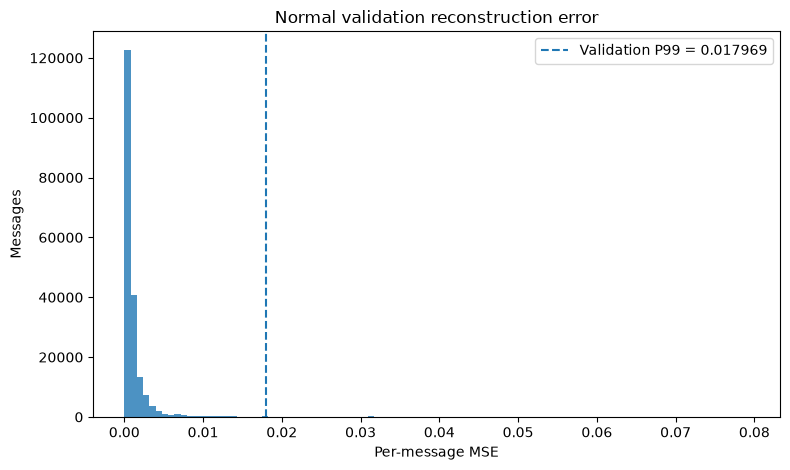

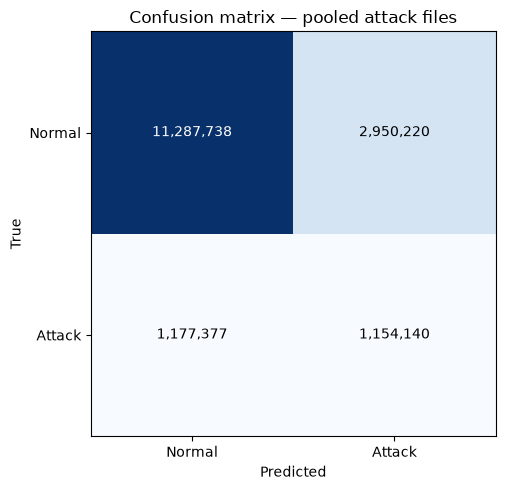

In [7]:
OUT = Path('results_tuned')
FIG = OUT / 'figures'
FIG.mkdir(parents=True, exist_ok=True)
plt.figure(figsize=(8,4.8))
plt.hist(val_scores, bins=100, alpha=.8)
plt.axvline(threshold, linestyle='--',label=f'Validation P{PERCENTILE:g} = {threshold:.5g}')
plt.title('Normal validation reconstruction error')
plt.xlabel('Per-message MSE')
plt.ylabel('Messages')
plt.legend()
plt.tight_layout()
plt.savefig(FIG/'01_validation_error_threshold.png',dpi=160)
plt.show()

cm = [[pooled['TN'], pooled['FP']], [pooled['FN'], pooled['TP']]]
cm = np.array(cm)
plt.figure(figsize=(5.6,5))
plt.imshow(cm, cmap='Blues')
plt.xticks([0,1],['Normal','Attack'])
plt.yticks([0,1],['Normal','Attack'])
plt.xlabel('Predicted')
plt.ylabel('True')
plt.title('Confusion matrix — pooled attack files')
for i in range(2):
    for j in range(2):
        plt.text(j,i,f'{cm[i,j]:,}',ha='center',va='center',color='white' if cm[i,j] > cm.max()/2 else 'black')
plt.tight_layout()
plt.savefig(FIG/'02_confusion_matrix.png',dpi=160)
plt.show()

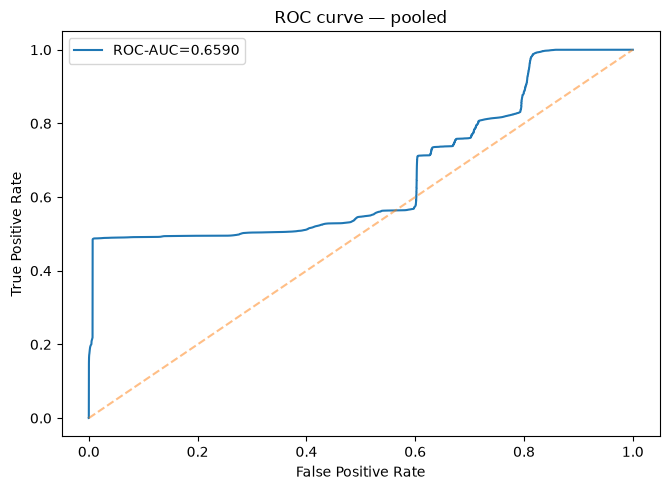

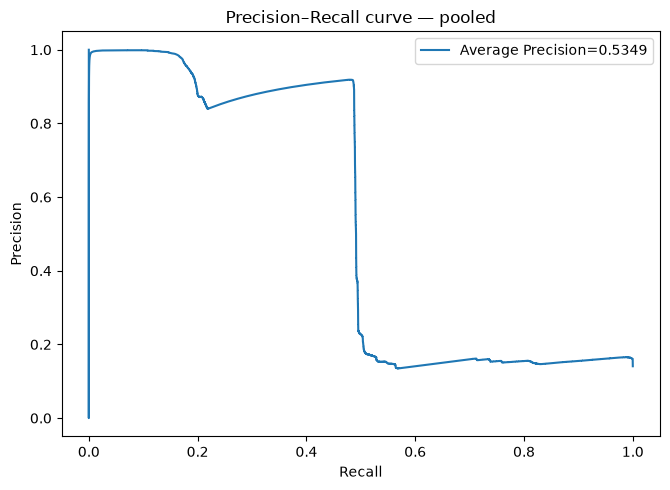

In [8]:
fpr,tpr,_ = roc_curve(all_labels, all_scores)
plt.figure(figsize=(6.8,5))
plt.plot(fpr,tpr,label=f"ROC-AUC={pooled['roc_auc']:.4f}")
plt.plot([0,1],[0,1],'--',alpha=.5)
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC curve — pooled')
plt.legend()
plt.tight_layout()
plt.savefig(FIG/'03_roc_curve.png',dpi=160)
plt.show()

prec,rec,_ = precision_recall_curve(all_labels, all_scores)
plt.figure(figsize=(6.8,5))
plt.plot(rec,prec,label=f"Average Precision={pooled['average_precision']:.4f}")
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision–Recall curve — pooled')
plt.legend()
plt.tight_layout()
plt.savefig(FIG/'04_pr_curve.png',dpi=160)
plt.show()

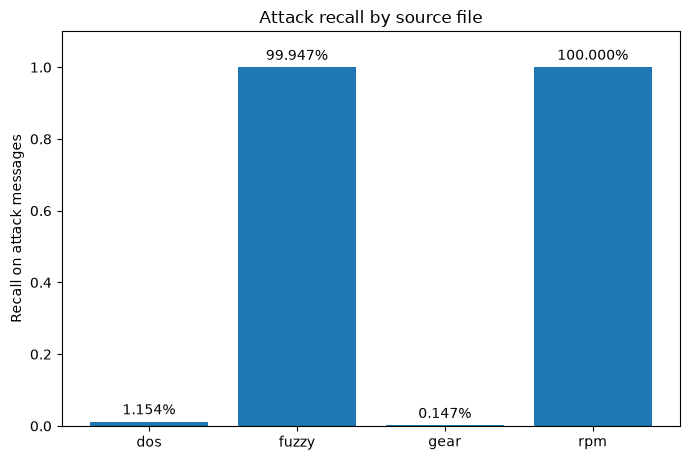

In [9]:
names=list(TESTS)
values=[metrics[n]['recall'] for n in names]
plt.figure(figsize=(7,4.7))
bars = plt.bar(names,values)
plt.bar_label(bars, labels=[f'{v:.3%}' for v in values], padding=3)
plt.ylim(0,1.10)
plt.ylabel('Recall on attack messages')
plt.title('Attack recall by source file')
plt.tight_layout()
plt.savefig(FIG/'05_per_attack_recall.png',dpi=160)
plt.show()

## 8. Save Results
Save computed results separately. The original result files provide a reference for comparison.

In [10]:
threshold_info = {
    'model_filename': MODEL.name,
    'validation_filename': VALIDATION.name,
    'method': 'normal_validation_percentile',
    'percentile': PERCENTILE,
    'threshold': threshold,
    'classification_rule': 'attack if reconstruction_mse > threshold'
}
(OUT / 'frozen_threshold.json').write_text(json.dumps(threshold_info, indent=2))
(OUT / 'evaluation_metrics.json').write_text(
    json.dumps({'threshold': threshold_info, 'metrics': metrics}, indent=2)
)
metrics_table.to_csv(OUT / 'metrics_per_attack.csv', index_label='attack_type')

report = [
    '# CarShield AI — Tuned Temporal Model Evaluation', '',
    f'Validation P99 threshold: {threshold:.12f}', '',
    '## Recall by attack', '',
]
for attack in TESTS:
    row = metrics[attack]
    report.append(f"- {attack}: {row['recall']:.3%} ({row['TP']:,} of {row['attack']:,} attacks)")
report.extend([
    '', f"Pooled recall: {pooled['recall']:.2%}. Pooled F1: {pooled['f1']:.2%}.",
    f"False positive rate among normal test messages: {pooled['fpr']:.2%}.",
    '', 'Pooled results count each message once. The team used the normal validation',
    'recording during model development. Results are reported per message.'
])
(OUT / 'evaluation_report.md').write_text(chr(10).join(report) + chr(10), encoding='utf-8')
print(f'Results saved to {OUT}/')

baseline = json.loads(Path('results_simple/evaluation_metrics.json').read_text())
comparison = []
metric_names = ['accuracy', 'precision', 'recall', 'f1', 'fpr', 'roc_auc', 'average_precision']
for attack, tuned in metrics.items():
    previous = baseline['metrics'][attack]
    if any(tuned[key] != previous[key] for key in ('n', 'normal', 'attack')):
        raise ValueError(f'{attack}: baseline and tuned sample counts differ.')
    for metric in metric_names:
        comparison.append({
            'evaluation': attack,
            'metric': metric,
            'baseline': previous[metric],
            'tuned': tuned[metric],
            'change': tuned[metric] - previous[metric]
        })
comparison = pd.DataFrame(comparison)
comparison.to_csv(OUT / 'baseline_vs_tuned.csv', index=False)
display(comparison[comparison['evaluation'] == 'pooled'].round(6))


Results saved to results_tuned/


,evaluation,metric,baseline,tuned,change
28,pooled,accuracy,0.868122,0.750892,-0.117230
29,pooled,precision,0.534441,0.281199,-0.253242
30,pooled,recall,0.487058,0.495017,0.007958
31,pooled,f1,0.509651,0.358658,-0.150992
32,pooled,fpr,0.069478,0.207208,0.137730
33,pooled,roc_auc,0.773507,0.658993,-0.114513
34,pooled,average_precision,0.597227,0.534862,-0.062365
